<a href="https://colab.research.google.com/github/GauthamAB/BIS/blob/main/ComSchRoutingACO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 10: Best distance = 76.00
Iteration 20: Best distance = 76.00
Iteration 30: Best distance = 76.00
Iteration 40: Best distance = 76.00
Iteration 50: Best distance = 76.00
Iteration 60: Best distance = 76.00
Iteration 70: Best distance = 76.00
Iteration 80: Best distance = 76.00
Iteration 90: Best distance = 76.00
Iteration 100: Best distance = 76.00

Best route found:
2 -> 0 -> 1 -> 3 -> 4 -> 2
Total route distance: 76.00


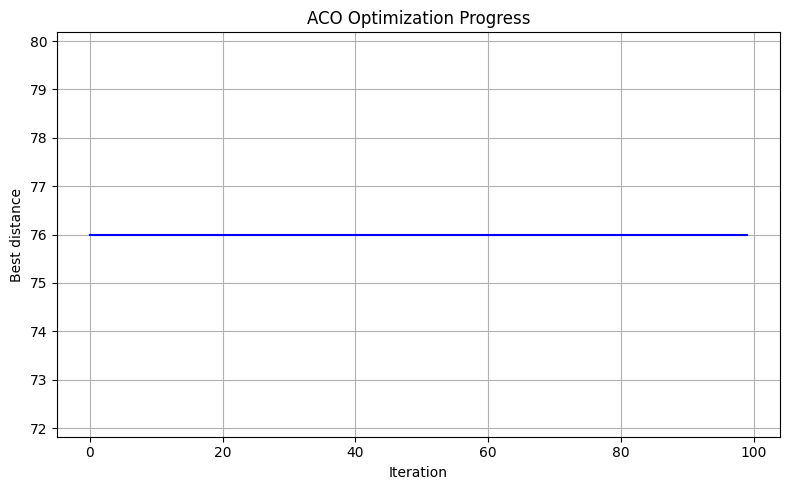

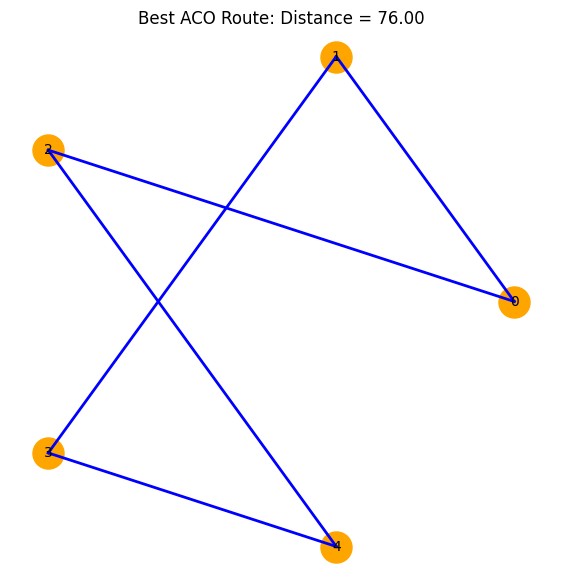

In [1]:

import numpy as np
import random
import matplotlib.pyplot as plt


class AntColonyOptimization:
    def __init__(
        self,
        distances,
        n_ants=10,
        n_iterations=100,
        alpha=1.0,
        beta=2.0,
        evaporation=0.5,
        Q=100
    ):
        self.distances = np.array(distances, dtype=float)
        self.n_cities = len(distances)
        self.n_ants = n_ants
        self.n_iterations = n_iterations
        self.alpha = alpha
        self.beta = beta
        self.evaporation = evaporation
        self.Q = Q

        # Avoid division by zero for identical-node distances
        self.heuristic = np.zeros_like(self.distances)
        mask = self.distances > 0
        self.heuristic[mask] = 1.0 / self.distances[mask]

        # Initialize pheromone levels
        self.pheromone = np.ones_like(self.distances)

        self.best_route = None
        self.best_distance = float("inf")
        self.history = []

    def calculate_distance(self, route):
        total = 0
        for i in range(len(route)):
            current_city = route[i]
            next_city = route[(i + 1) % len(route)]
            total += self.distances[current_city][next_city]
        return total

    def select_next_city(self, current_city, unvisited):
        probabilities = []

        for city in unvisited:
            pheromone = self.pheromone[current_city][city] ** self.alpha
            heuristic = self.heuristic[current_city][city] ** self.beta
            probabilities.append(pheromone * heuristic)

        probabilities = np.array(probabilities, dtype=float)

        # Handle numerical underflow
        if probabilities.sum() == 0:
            probabilities = np.ones(len(unvisited)) / len(unvisited)
        else:
            probabilities /= probabilities.sum()

        return random.choices(
            list(unvisited),
            weights=probabilities,
            k=1
        )[0]

    def run(self):
        for iteration in range(self.n_iterations):
            all_routes = []
            all_distances = []

            for _ in range(self.n_ants):
                start = random.randrange(self.n_cities)
                route = [start]
                unvisited = set(range(self.n_cities))
                unvisited.remove(start)

                while unvisited:
                    next_city = self.select_next_city(
                        route[-1], unvisited
                    )
                    route.append(next_city)
                    unvisited.remove(next_city)

                distance = self.calculate_distance(route)
                all_routes.append(route)
                all_distances.append(distance)

                if distance < self.best_distance:
                    self.best_distance = distance
                    self.best_route = route.copy()

            # Evaporate old pheromone
            self.pheromone *= (1 - self.evaporation)

            # Deposit pheromone on routes
            for route, distance in zip(all_routes, all_distances):
                deposit = self.Q / distance

                for i in range(self.n_cities):
                    a = route[i]
                    b = route[(i + 1) % self.n_cities]
                    self.pheromone[a][b] += deposit
                    self.pheromone[b][a] += deposit

            self.history.append(self.best_distance)

            if (iteration + 1) % 10 == 0:
                print(
                    f"Iteration {iteration + 1}: "
                    f"Best distance = {self.best_distance:.2f}"
                )

        return self.best_route, self.best_distance


# Example: distance matrix for five computer/network nodes
distances = [
    [0,  10, 15, 20, 12],
    [10,  0, 35, 25, 18],
    [15, 35,  0, 30, 10],
    [20, 25, 30,  0, 16],
    [12, 18, 10, 16,  0]
]

aco = AntColonyOptimization(
    distances=distances,
    n_ants=10,
    n_iterations=100,
    alpha=1.0,
    beta=2.0,
    evaporation=0.5,
    Q=100
)

best_route, best_distance = aco.run()

print("\nBest route found:")
print(" -> ".join(map(str, best_route + [best_route[0]])))
print(f"Total route distance: {best_distance:.2f}")

# Plot best distance over iterations
plt.figure(figsize=(8, 5))
plt.plot(aco.history, color="blue")
plt.xlabel("Iteration")
plt.ylabel("Best distance")
plt.title("ACO Optimization Progress")
plt.grid(True)
plt.tight_layout()
plt.show()

# Draw the route using circular node positions
angles = np.linspace(0, 2 * np.pi, len(distances), endpoint=False)
positions = np.column_stack((np.cos(angles), np.sin(angles)))

plt.figure(figsize=(7, 7))

for i, (x, y) in enumerate(positions):
    plt.scatter(x, y, s=500, color="orange")
    plt.text(x, y, str(i), ha="center", va="center")

closed_route = best_route + [best_route[0]]

for i in range(len(closed_route) - 1):
    a = positions[closed_route[i]]
    b = positions[closed_route[i + 1]]
    plt.plot(
        [a[0], b[0]],
        [a[1], b[1]],
        "b-",
        linewidth=2
    )

plt.title(f"Best ACO Route: Distance = {best_distance:.2f}")
plt.axis("equal")
plt.axis("off")
plt.show()
